In [29]:
import kagglehub
masoudnickparvar_brain_tumor_mri_dataset_path = kagglehub.dataset_download('masoudnickparvar/brain-tumor-mri-dataset')

print('Data source import complete.')

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Data source import complete.


In [30]:
import os
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from glob import glob

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import warnings
warnings.filterwarnings('ignore')

In [31]:
def train_df(tr_path):
    classes, class_paths = zip(*[(label, os.path.join(tr_path, label, image))
                                 for label in os.listdir(tr_path) if os.path.isdir(os.path.join(tr_path, label))
                                 for image in os.listdir(os.path.join(tr_path, label))])

    tr_df = pd.DataFrame({'Class Path': class_paths, 'Class': classes})
    return tr_df

In [32]:
def test_df(ts_path):
    classes, class_paths = zip(*[(label, os.path.join(ts_path, label, image))
                                 for label in os.listdir(ts_path) if os.path.isdir(os.path.join(ts_path, label))
                                 for image in os.listdir(os.path.join(ts_path, label))])

    ts_df = pd.DataFrame({'Class Path': class_paths, 'Class': classes})
    return ts_df

In [33]:
tr_df = train_df('/kaggle/input/brain-tumor-mri-dataset/Training')

In [34]:
tr_df

,Class Path,Class
0,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary
1,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary
2,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary
3,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary
4,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary
...,...,...
5595,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma
5596,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma
5597,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma
5598,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma


In [35]:
ts_df = test_df('/kaggle/input/brain-tumor-mri-dataset/Testing')

In [36]:
ts_df

,Class Path,Class
0,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
1,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
2,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
3,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
4,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
...,...,...
1595,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
1596,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
1597,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
1598,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma


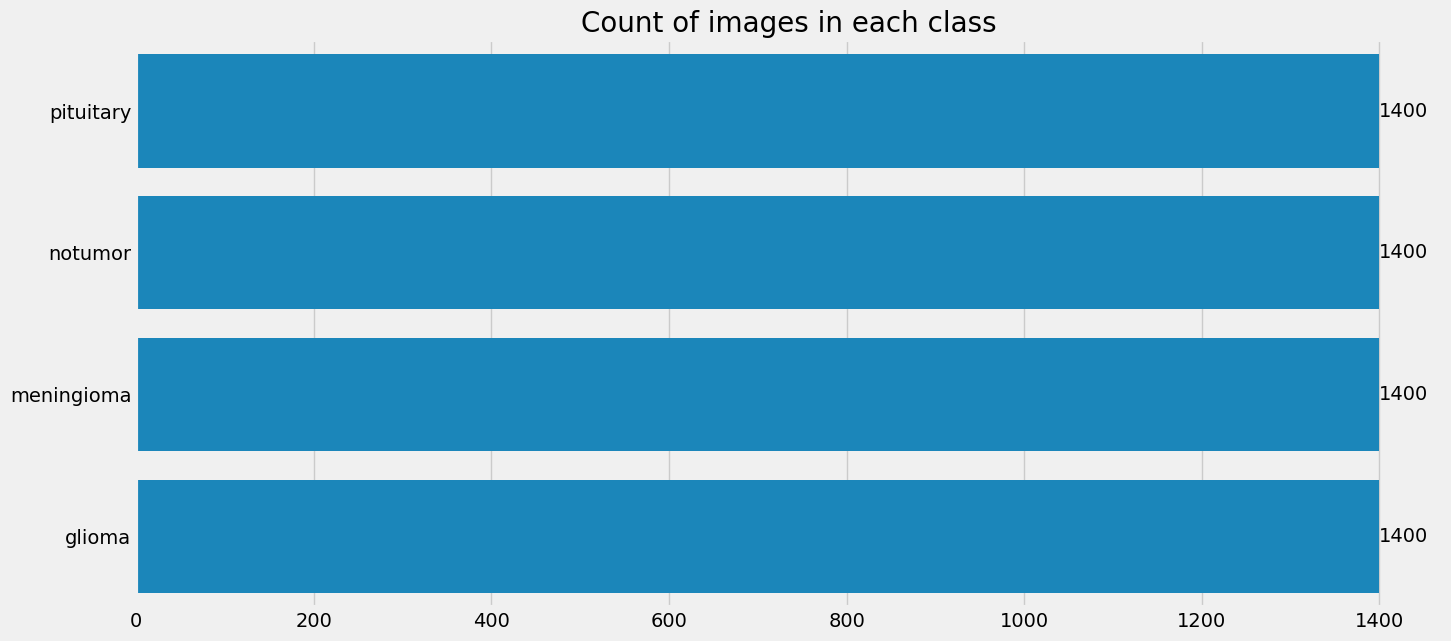

In [37]:
plt.figure(figsize=(15,7))
ax = sns.countplot(data=tr_df, y=tr_df['Class'])

plt.xlabel('')
plt.ylabel('')
plt.title('Count of images in each class', fontsize=20)
ax.bar_label(ax.containers[0])
plt.show()

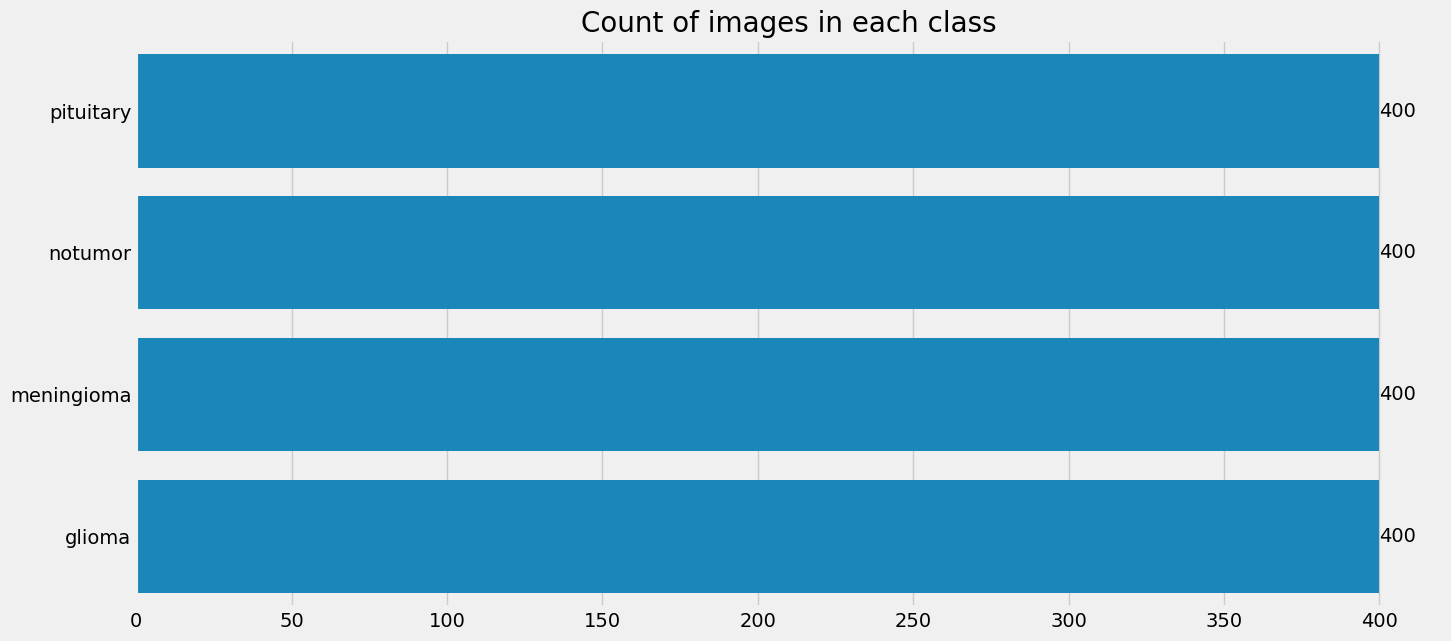

In [38]:
plt.figure(figsize=(15,7))
ax = sns.countplot(data=ts_df, y=ts_df['Class'])

plt.xlabel('')
plt.ylabel('')
plt.title('Count of images in each class', fontsize=20)
ax.bar_label(ax.containers[0])
plt.show()

In [39]:
valid_df, ts_df = train_test_split(ts_df, train_size=0.5, random_state=20, stratify=ts_df["Class"])

In [40]:
valid_df

,Class Path,Class
198,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
857,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma
1098,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma
1119,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma
508,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor
...,...,...
1281,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
172,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
792,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor
933,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma


In [41]:
batch_size = 32
img_size = (299, 299)

_gen = ImageDataGenerator(rescale=1/255, brightness_range=(0.8, 1.2))

ts_gen = ImageDataGenerator(rescale=1/255)

tr_gen = _gen.flow_from_dataframe(
    tr_df,
    x_col = "Class Path",
    y_col = "Class",
    batch_size = batch_size,
    target_size = img_size
    )

valid_gen = _gen.flow_from_dataframe(
    valid_df,
    x_col = "Class Path",
    y_col = "Class",
    batch_size = batch_size,
    target_size = img_size
)

ts_gen = ts_gen.flow_from_dataframe(
    ts_df,
    x_col = "Class Path",
    y_col = "Class",
    batch_size = 16,
    target_size = img_size,
    shuffle = False
)

Found 5600 validated image filenames belonging to 4 classes.
Found 800 validated image filenames belonging to 4 classes.
Found 800 validated image filenames belonging to 4 classes.


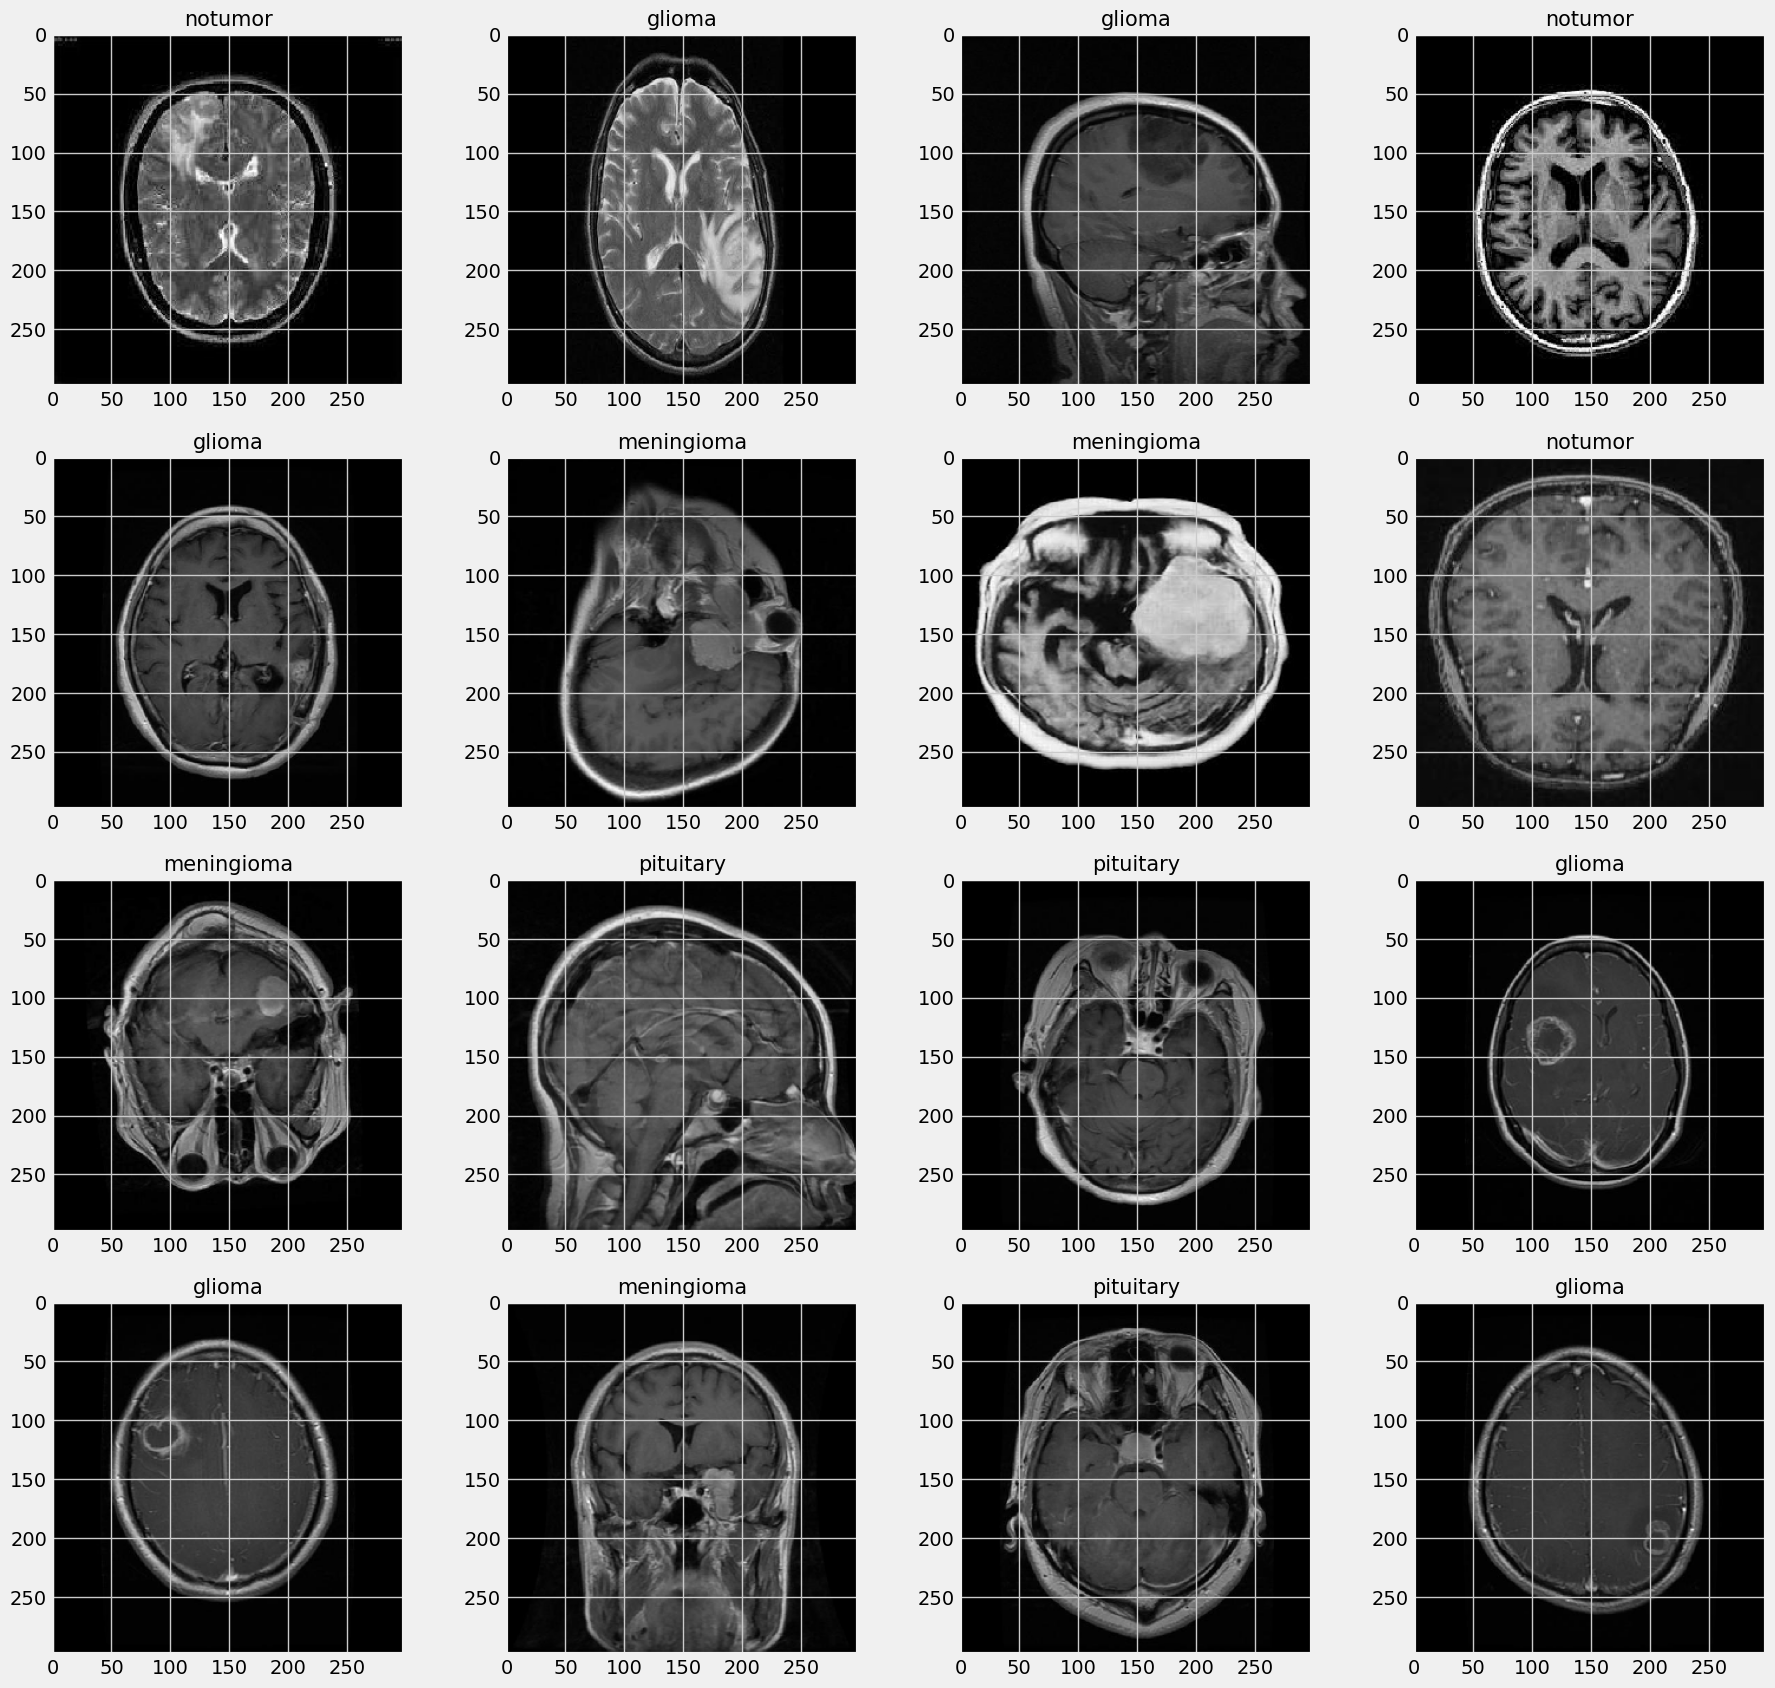

In [42]:
class_dict = tr_gen.class_indices
classes = list(class_dict.keys())
images, labels = next(ts_gen)

plt.figure(figsize=(20, 20))

for i, (image, label) in enumerate(zip(images, labels)):
    plt.subplot(4, 4, i+1)
    plt.imshow(image)
    class_name = classes[np.argmax(label)]
    plt.title(class_name, color = "k", fontsize = 15)

plt.show()

In [43]:
img_shape = (299, 299, 3)
base_model = tf.keras.applications.Xception(include_top = False, weights = "imagenet", input_shape = img_shape, pooling = "max")

model = Sequential([
    base_model,
    Flatten(),
    Dropout(rate = 0.3),
    Dense(128, activation = "relu"),
    Dropout(rate = 0.5),
    Dense(4, activation = "softmax")
])

model.compile(Adamax(learning_rate = 0.001),
              loss = "categorical_crossentropy",
              metrics = ["accuracy",
                          Precision(),
                          Recall()]
              )

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,124,268 (80.58 MB)

 Trainable params: 21,069,740 (80.37 MB)

 Non-trainable params: 54,528 (213.00 KB)

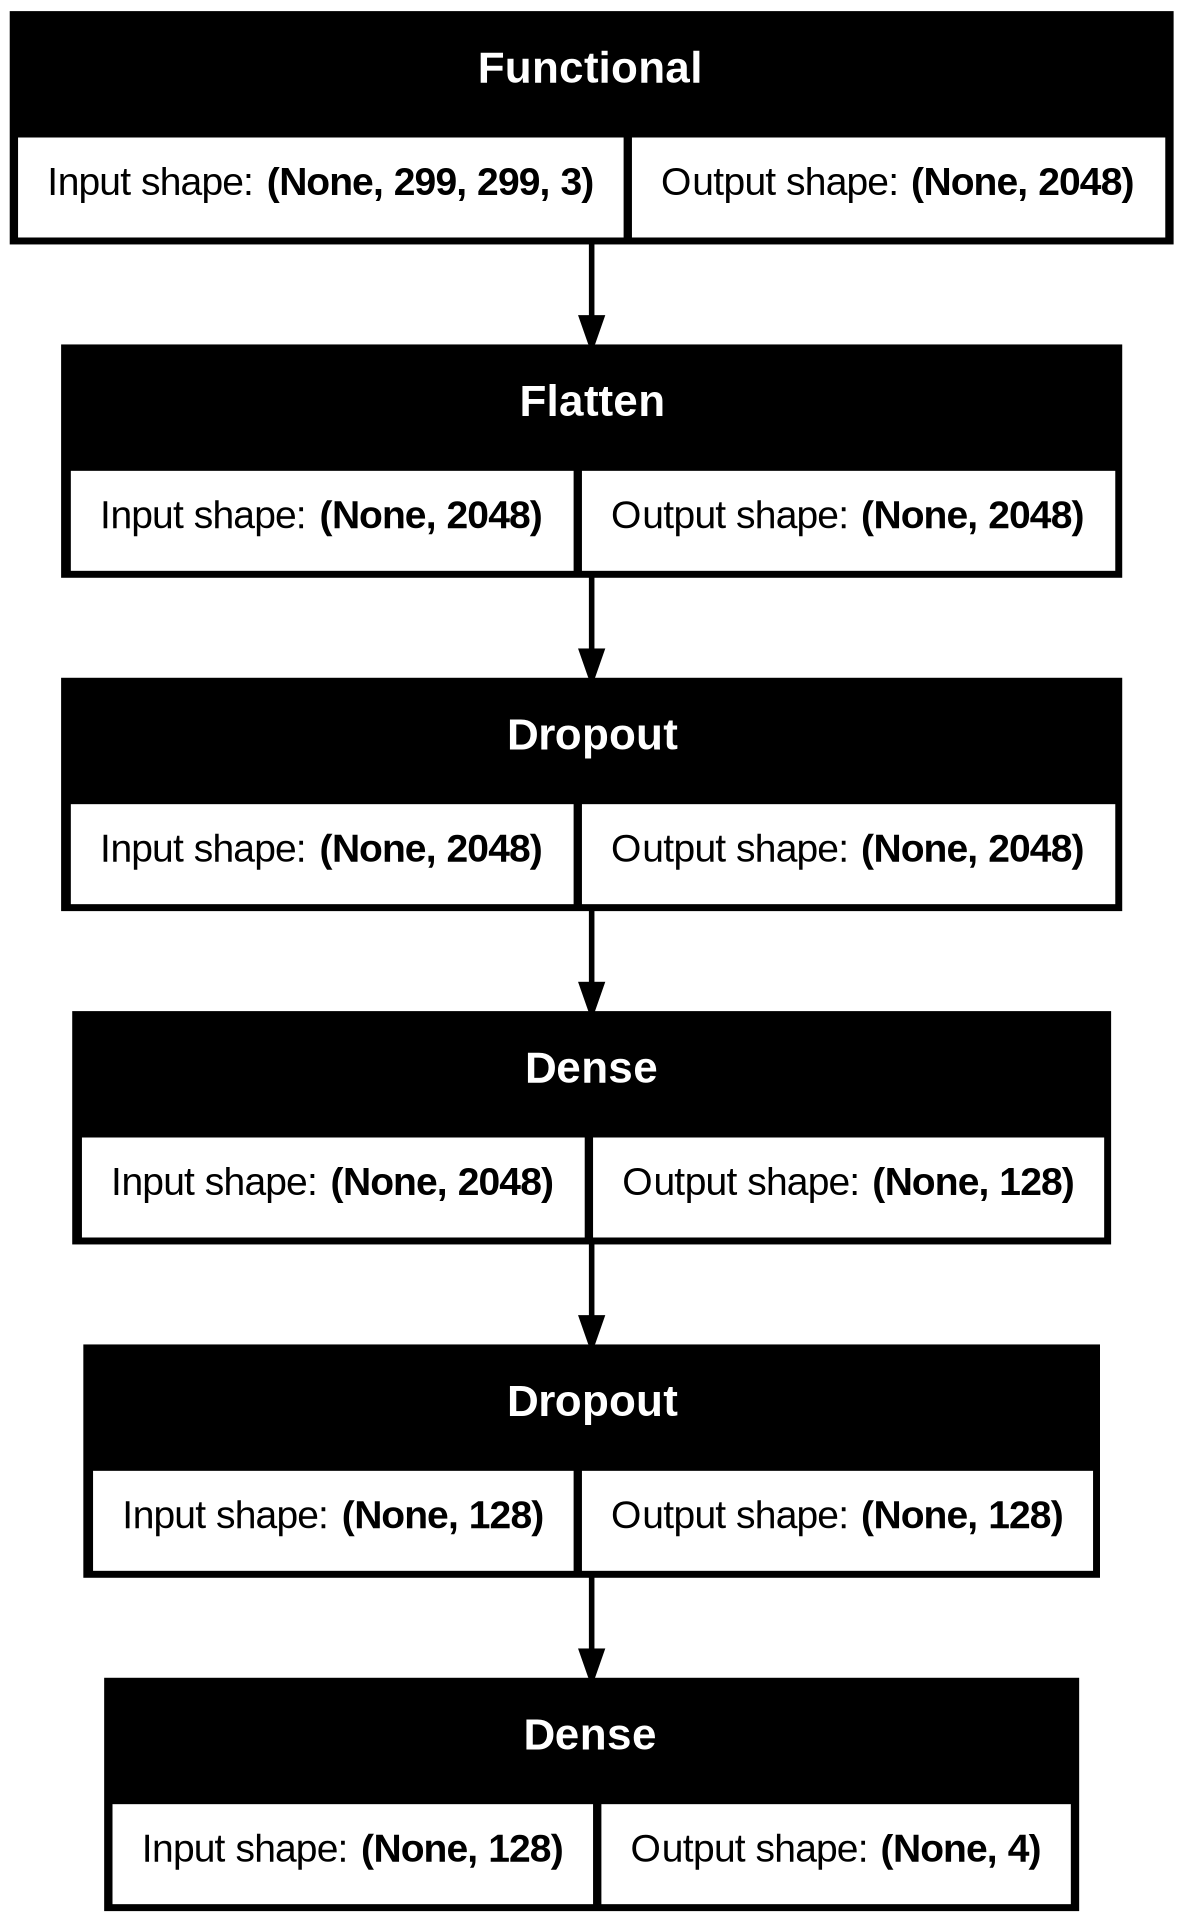

In [44]:
tf.keras.utils.plot_model(model, show_shapes = True)

In [45]:
hist = model.fit(tr_gen,
                 epochs = 10,
                 validation_data = valid_gen,
                 shuffle = False)

Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 211s 997ms/step - accuracy: 0.8559 - loss: 0.4112 - precision_1: 0.9028 - recall_1: 0.8011 - val_accuracy: 0.7987 - val_loss: 0.8104 - val_precision_1: 0.8127 - val_recall_1: 0.7812
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 170s 971ms/step - accuracy: 0.9718 - loss: 0.0898 - precision_1: 0.9736 - recall_1: 0.9689 - val_accuracy: 0.9150 - val_loss: 0.3490 - val_precision_1: 0.9208 - val_recall_1: 0.9150
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 170s 968ms/step - accuracy: 0.9893 - loss: 0.0407 - precision_1: 0.9903 - recall_1: 0.9887 - val_accuracy: 0.9413 - val_loss: 0.3648 - val_precision_1: 0.9411 - val_recall_1: 0.9388
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 171s 973ms/step - accuracy: 0.9925 - loss: 0.0285 - precision_1: 0.9930 - recall_1: 0.9920 - val_accuracy: 0.9463 - val_loss: 0.2843 - val_precision_1: 0.9472 - val_recall_1: 0.9425
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 170s 973ms/step - accuracy: 0.9962 - loss: 0.0160 - precision_1: 0.9962 

In [48]:
hist.history.keys()

dict_keys(['accuracy', 'loss', 'precision_1', 'recall_1', 'val_accuracy', 'val_loss', 'val_precision_1', 'val_recall_1'])

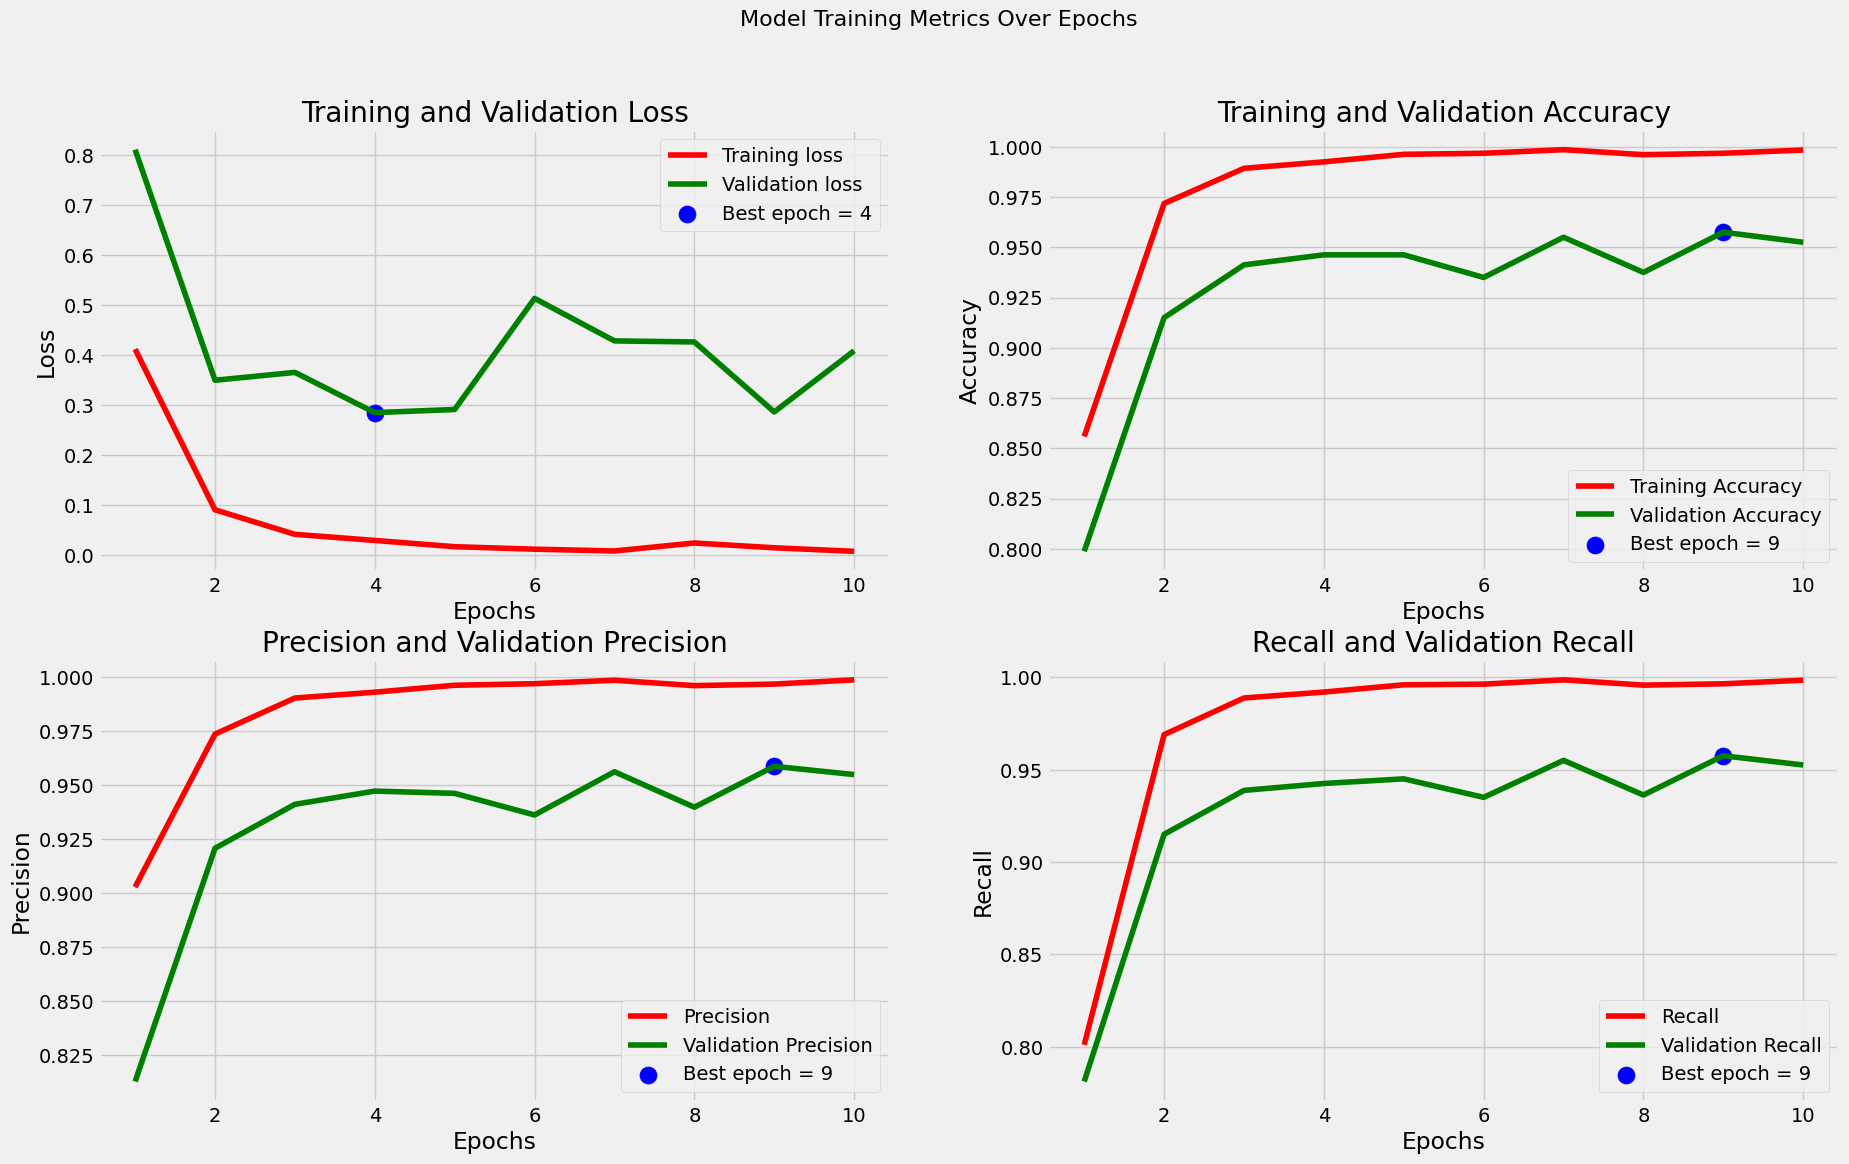

In [52]:
tr_acc = hist.history['accuracy']
tr_loss = hist.history['loss']

tr_per_key = next((k for k in hist.history.keys() if 'precision' in k and 'val' not in k), 'precision')
tr_recall_key = next((k for k in hist.history.keys() if 'recall' in k and 'val' not in k), 'recall')
val_per_key = next((k for k in hist.history.keys() if 'precision' in k and 'val' in k), 'val_precision')
val_recall_key = next((k for k in hist.history.keys() if 'recall' in k and 'val' in k), 'val_recall')

tr_per = hist.history[tr_per_key]
tr_recall = hist.history[tr_recall_key]
val_acc = hist.history['val_accuracy']
val_loss = hist.history['val_loss']
val_per = hist.history[val_per_key]
val_recall = hist.history[val_recall_key]

index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
index_precision = np.argmax(val_per)
per_highest = val_per[index_precision]
index_recall = np.argmax(val_recall)
recall_highest = val_recall[index_recall]

Epochs = [i + 1 for i in range(len(tr_acc))]
loss_label = f'Best epoch = {str(index_loss + 1)}'
acc_label = f'Best epoch = {str(index_acc + 1)}'
per_label = f'Best epoch = {str(index_precision + 1)}'
recall_label = f'Best epoch = {str(index_recall + 1)}'


plt.figure(figsize=(20, 12))
plt.style.use('fivethirtyeight')


plt.subplot(2, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label='Training loss')
plt.plot(Epochs, val_loss, 'g', label='Validation loss')
plt.scatter(index_loss + 1, val_lowest, s=150, c='blue', label=loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label='Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label='Validation Accuracy')
plt.scatter(index_acc + 1, acc_highest, s=150, c='blue', label=acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(Epochs, tr_per, 'r', label='Precision')
plt.plot(Epochs, val_per, 'g', label='Validation Precision')
plt.scatter(index_precision + 1, per_highest, s=150, c='blue', label=per_label)
plt.title('Precision and Validation Precision')
plt.xlabel('Epochs')
plt.ylabel('Precision')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 4)
plt.plot(Epochs, tr_recall, 'r', label='Recall')
plt.plot(Epochs, val_recall, 'g', label='Validation Recall')
plt.scatter(index_recall + 1, recall_highest, s=150, c='blue', label=recall_label)
plt.title('Recall and Validation Recall')
plt.xlabel('Epochs')
plt.ylabel('Recall')
plt.legend()
plt.grid(True)

plt.suptitle('Model Training Metrics Over Epochs', fontsize=16)
plt.show()

In [53]:
train_score = model.evaluate(tr_gen, verbose=1)
valid_score = model.evaluate(valid_gen, verbose=1)
test_score = model.evaluate(ts_gen, verbose=1)

print(f"Train Loss: {train_score[0]:.4f}")
print(f"Train Accuracy: {train_score[1]*100:.2f}")


print(f"Validation Loss: {valid_score[0]:.4f}")
print(f"Validation Accuracy: {valid_score[1]*100:.2f}")


print(f"Test Loss: {test_score[0]:.4f}")
print(f"Test Accuracy: {test_score[1]*100:.2f}")

175/175 ━━━━━━━━━━━━━━━━━━━━ 47s 268ms/step - accuracy: 1.0000 - loss: 1.3282e-04 - precision_1: 1.0000 - recall_1: 1.0000
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 315ms/step - accuracy: 0.9550 - loss: 0.4046 - precision_1: 0.9562 - recall_1: 0.9550
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 122ms/step - accuracy: 0.9563 - loss: 0.3991 - precision_1: 0.9598 - recall_1: 0.9550
Train Loss: 0.0001
Train Accuracy: 100.00
Validation Loss: 0.4046
Validation Accuracy: 95.50
Test Loss: 0.3991
Test Accuracy: 95.63


In [54]:
preds = model.predict(ts_gen)
y_pred = np.argmax(preds, axis=1)

50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 127ms/step


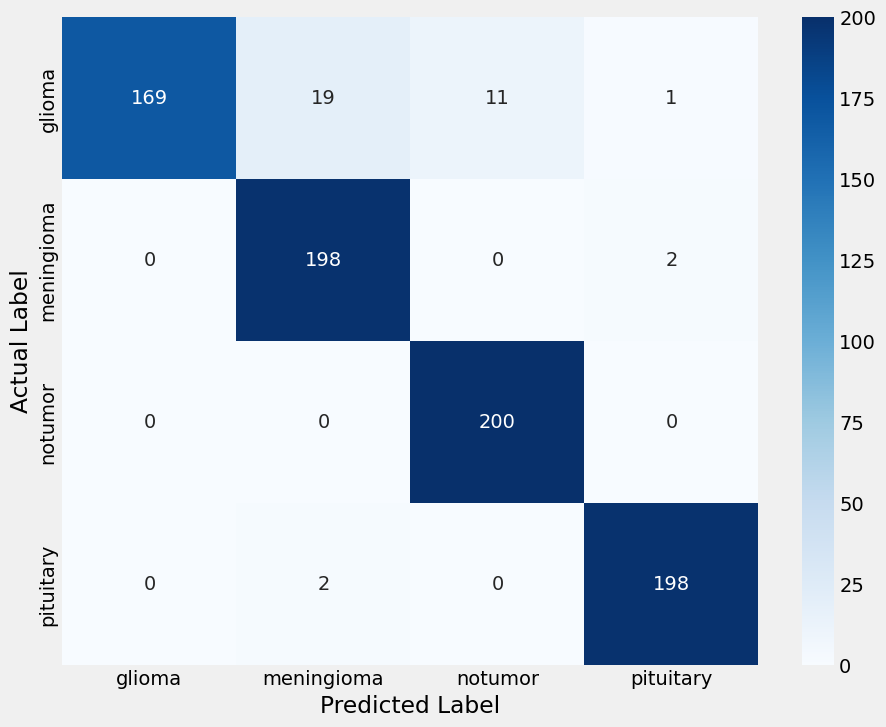

In [55]:
cm = confusion_matrix(ts_gen.classes, y_pred)
labels = list(class_dict.keys())
plt.figure(figsize=(10,8))
sns.heatmap(cm,
            annot = True,
            fmt = "d",
            cmap = "Blues",
            xticklabels = labels,
            yticklabels = labels)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [56]:
clr = classification_report(ts_gen.classes, y_pred)
print(clr)

              precision    recall  f1-score   support

           0       1.00      0.84      0.92       200
           1       0.90      0.99      0.95       200
           2       0.95      1.00      0.97       200
           3       0.99      0.99      0.99       200

    accuracy                           0.96       800
   macro avg       0.96      0.96      0.96       800
weighted avg       0.96      0.96      0.96       800



In [57]:
def predict(img):
  # import numpy as np
  # import matplotlib.pyplot as plt
  # from PIL import Image

  label = list(class_dict.keys())
  plt.figure(figsize = (12, 12))
  pic = Image.open(img)
  resized_pic = pic.resize((299, 299))
  pic = np.asarray(resized_pic)
  pic = np.expand_dims(pic, axis = 0)
  pic = pic / 255
  predicitions = model.predict(pic)
  probs = list(predicitions[0])
  labels = label

  plt.subplot(2, 1, 1)
  plt.imshow(resized_pic)
  plt.subplot(2, 1, 2)

  bars = plt.barh(labels, probs)
  plt.xlabel("Probability", fontsize=15)
  ax = plt.gca()
  ax.bar_label(bars, fmt = "%.2f")
  plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


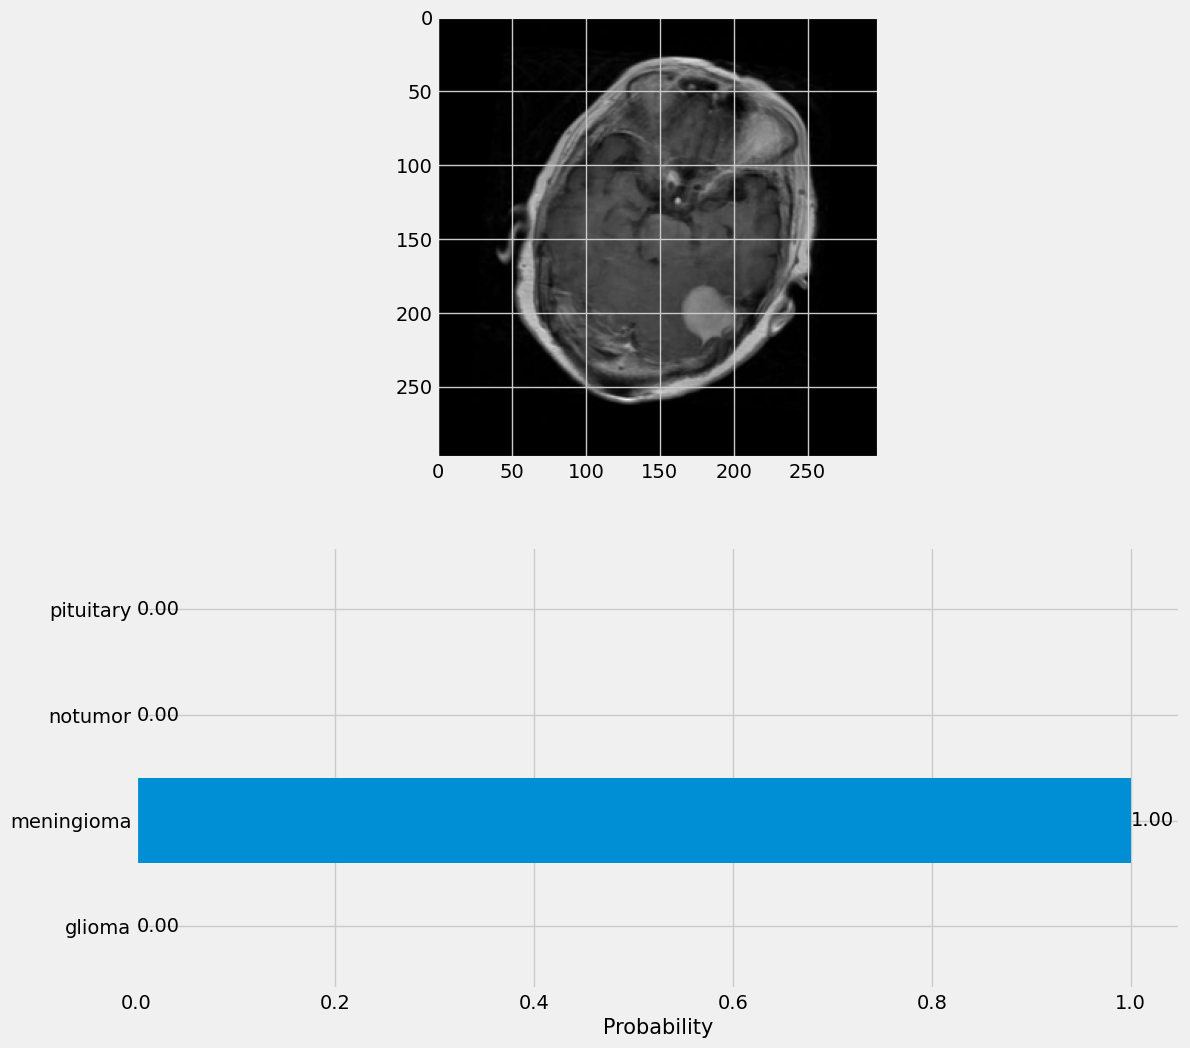

In [58]:
predict('/kaggle/input/brain-tumor-mri-dataset/Testing/meningioma/Te-aug-me_1.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


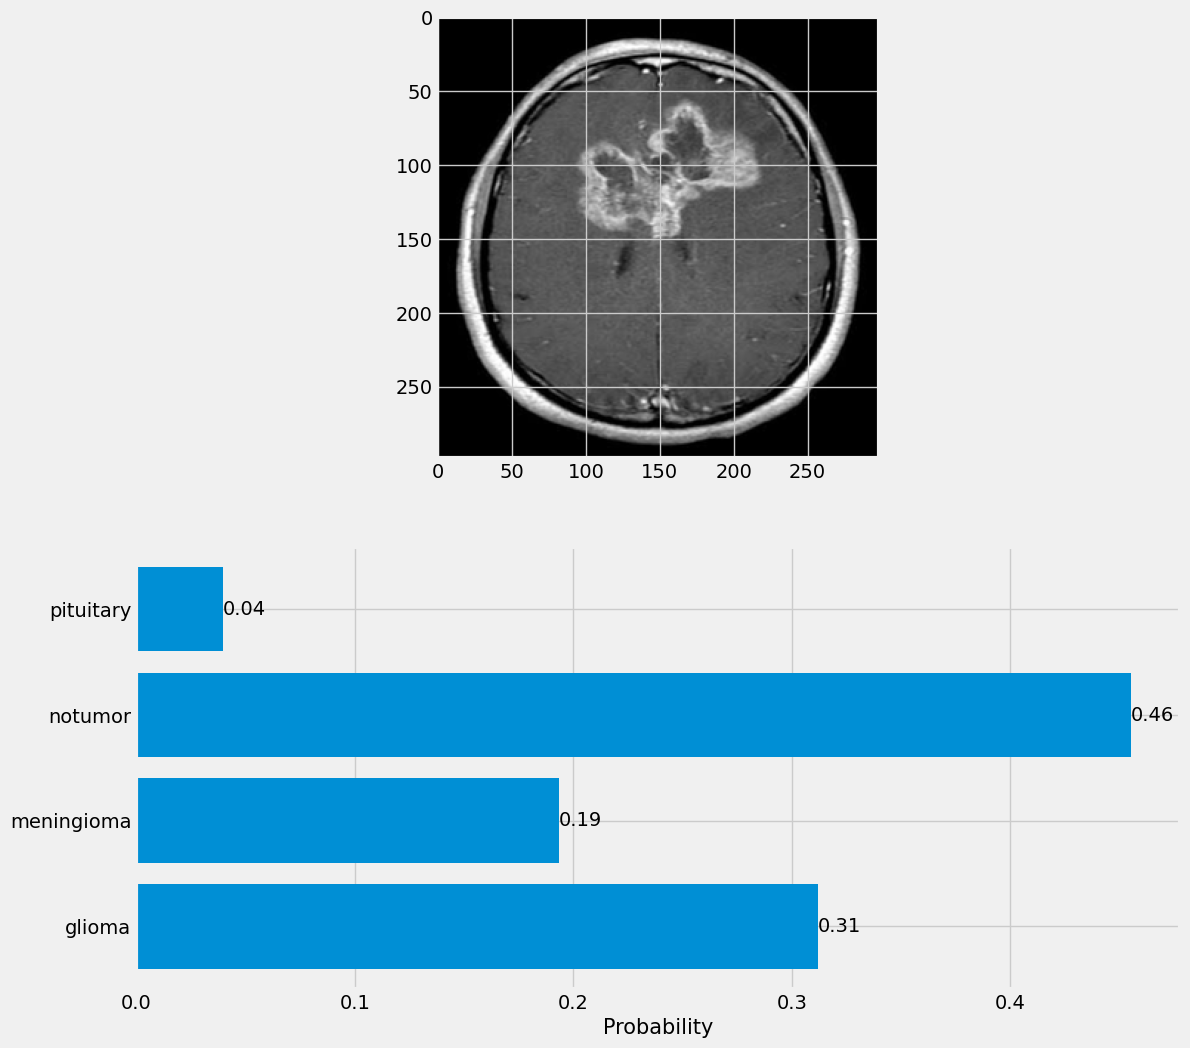

In [59]:
predict('/kaggle/input/brain-tumor-mri-dataset/Testing/glioma/Te-gl_1.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


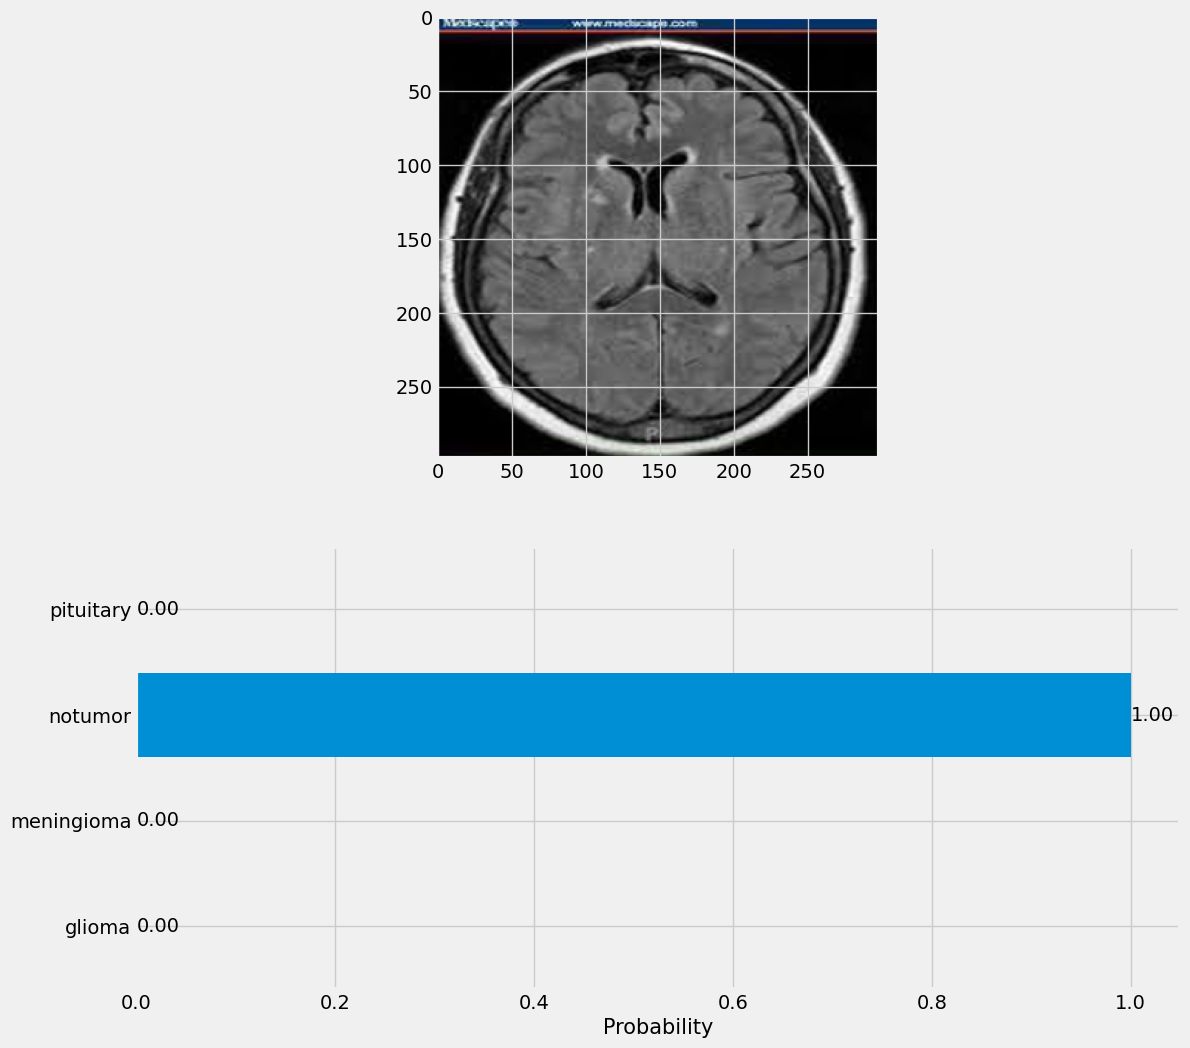

In [60]:
predict('/kaggle/input/brain-tumor-mri-dataset/Testing/notumor/Te-no_1.jpg')

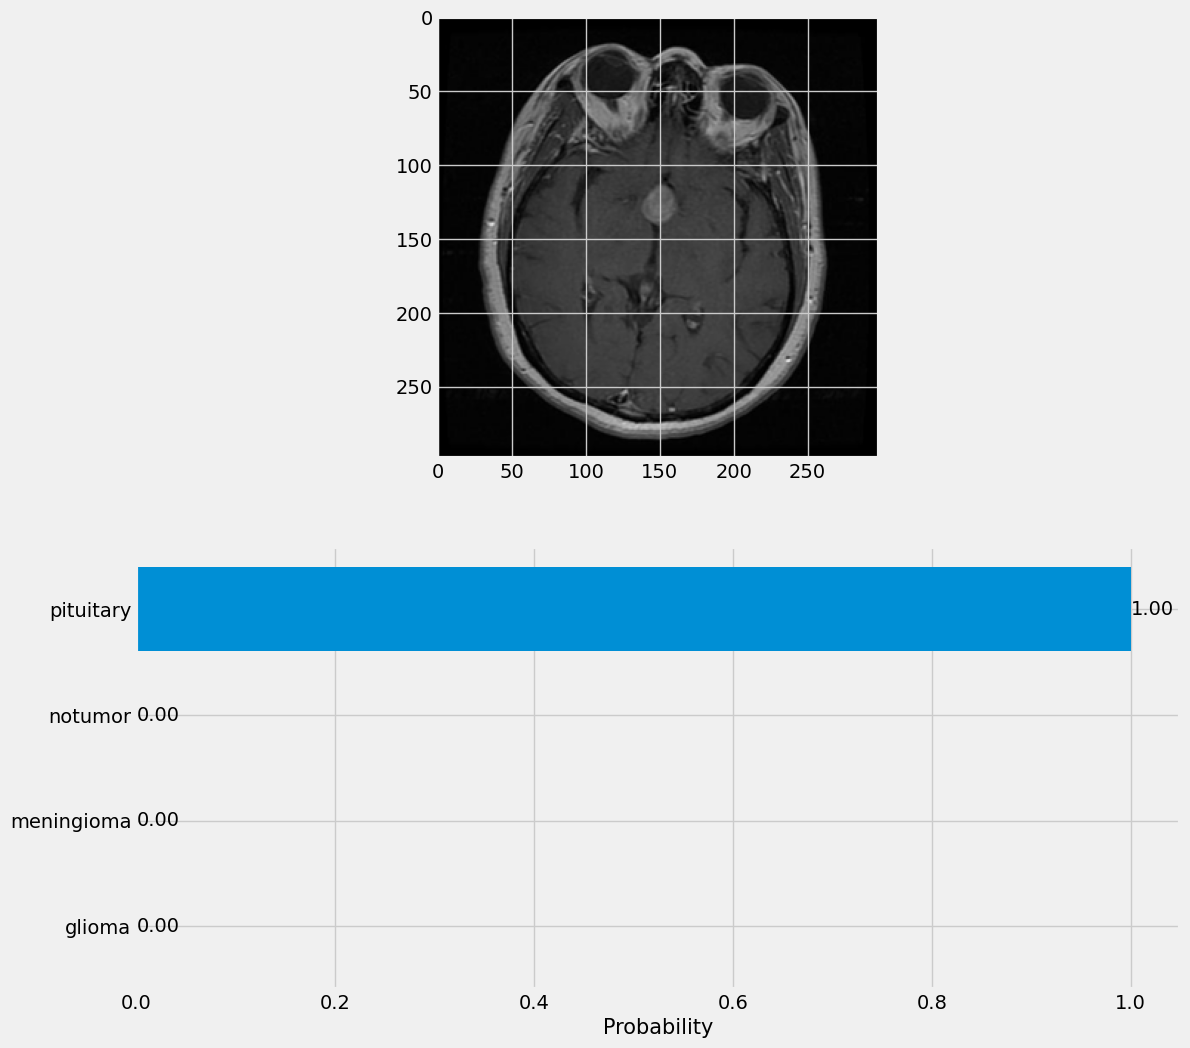

In [71]:
def predict_fixed(img):
  label = list(class_dict.keys())
  plt.figure(figsize = (12, 12))

  pic = Image.open(img).convert('RGB')
  resized_pic = pic.resize((299, 299))
  pic = np.asarray(resized_pic, dtype=np.float32)
  pic = np.expand_dims(pic, axis = 0)
  pic = pic / 255.0

  tensor_pic = tf.convert_to_tensor(pic)
  tensor_pic.set_shape([1, 299, 299, 3])

  predictions = model(tensor_pic, training=False)
  probs = list(predictions.numpy()[0])
  labels = label

  plt.subplot(2, 1, 1)
  plt.imshow(resized_pic)
  plt.subplot(2, 1, 2)

  bars = plt.barh(labels, probs)
  plt.xlabel("Probability", fontsize=15)
  ax = plt.gca()
  ax.bar_label(bars, fmt = "%.2f")
  plt.show()

predict_fixed("/kaggle/input/brain-tumor-mri-dataset/Testing/pituitary/Te-pi_11.jpg")

In [65]:
for layer in model.layers:
    print(layer.name, layer.__class__.__name__)

xception Functional
flatten_1 Flatten
dropout_2 Dropout
dense_2 Dense
dropout_3 Dropout
dense_3 Dense


In [66]:
import cv2

In [67]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        model.inputs, [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

In [68]:
def display_gradcam(img_path, heatmap, alpha = 0.4):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    heatmap = np.uint8(255 * heatmap)

    jet = cv2.COLORMAP_JET
    jet_heatmap = cv2.applyColorMap(heatmap, jet)
    jet_heatmap = cv2.cvtColor(jet_heatmap, cv2.COLOR_BGR2RGB)

    jet_heatmap = cv2.resize(jet_heatmap, (img.shape[1], img.shape[0]))

    superimposed_img = cv2.addWeighted(img, 1 - alpha, jet_heatmap, alpha, 0)

    plt.figure(figsize = (8, 8))
    plt.imshow(superimposed_img)
    plt.axis("off")
    plt.show()

In [69]:
def heat_path(img_path):
  img_size = (224, 224)
  img = tf.keras.utils.load_img(img_path, target_size=img_size)
  x = tf.keras.utils.img_to_array(img)
  x = np.expand_dims(x, axis = 0)

  last_conv_layer_name = "conv5_blocks3_out"

  heatmap = make_gradcam_heatmap(x, model, last_conv_layer_name)

  display_gradcam(img_path, heatmap)

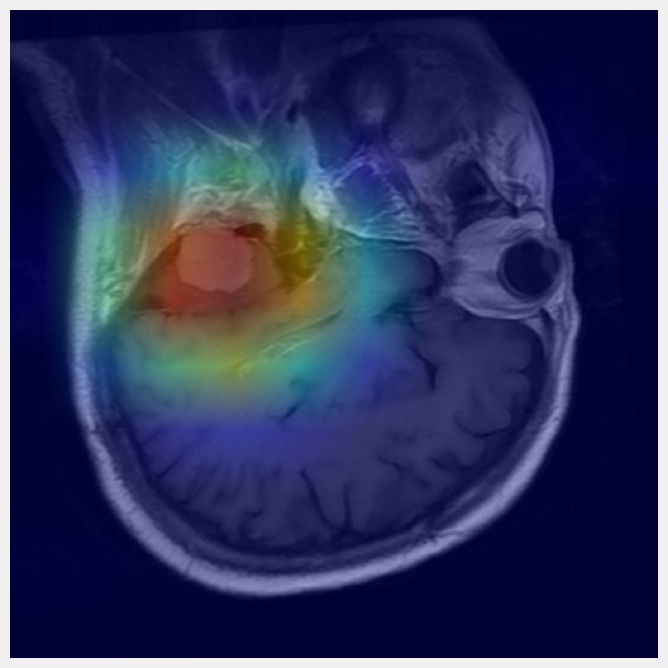

In [73]:
def heat_path_xception(img_path):
  img_size = (299, 299)
  img = tf.keras.utils.load_img(img_path, target_size=img_size)
  x = tf.keras.utils.img_to_array(img)
  x = np.expand_dims(x, axis = 0)
  x = x / 255.0

  last_conv_layer_name = "block14_sepconv2_act"

  base_model_xception = model.get_layer("xception")
  heatmap = make_gradcam_heatmap(x, base_model_xception, last_conv_layer_name)

  display_gradcam(img_path, heatmap)

heat_path_xception('/kaggle/input/brain-tumor-mri-dataset/Testing/meningioma/Te-aug-me_19.jpg')